In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

from joblib import Parallel, delayed

print("Library untuk eksperimen komputasi siap!")

Library untuk eksperimen komputasi siap!


In [2]:
np.random.seed(42)

jumlah_data = 1_000_000
data = np.random.random(jumlah_data)

print("Jumlah data:", len(data))
print("Lima data pertama:", data[:5])
print("Ukuran data:", round(data.nbytes / (1024**2), 2), "MB")

Jumlah data: 1000000
Lima data pertama: [0.37454012 0.95071431 0.73199394 0.59865848 0.15601864]
Ukuran data: 7.63 MB


In [3]:
def proses_data(bagian):
    hasil = bagian.copy()

    for _ in range(20):
        hasil = np.sqrt(hasil + 1.0) * 0.5

    return hasil

print("Fungsi komputasi berhasil dibuat!")

Fungsi komputasi berhasil dibuat!


In [4]:
jumlah_bagian = 8
bagian_data = np.array_split(data, jumlah_bagian)

mulai_serial = time.perf_counter()

hasil_serial = [
    proses_data(bagian)
    for bagian in bagian_data
]

waktu_serial = time.perf_counter() - mulai_serial

hasil_serial = np.concatenate(hasil_serial)

print(f"Waktu pemrosesan serial: {waktu_serial:.4f} detik")
print("Jumlah hasil:", len(hasil_serial))

Waktu pemrosesan serial: 0.1220 detik
Jumlah hasil: 1000000


In [5]:
jumlah_proses = 2

mulai_paralel = time.perf_counter()

hasil_paralel = Parallel(n_jobs=jumlah_proses)(
    delayed(proses_data)(bagian)
    for bagian in bagian_data
)

waktu_paralel = time.perf_counter() - mulai_paralel

hasil_paralel = np.concatenate(hasil_paralel)

print(f"Jumlah proses: {jumlah_proses}")
print(f"Waktu pemrosesan paralel: {waktu_paralel:.4f} detik")
print("Jumlah hasil:", len(hasil_paralel))

Jumlah proses: 2
Waktu pemrosesan paralel: 0.7062 detik
Jumlah hasil: 1000000


===== PERBANDINGAN PERFORMA =====
Serial  : 0.1220 detik
Paralel : 0.7062 detik
Rasio waktu serial terhadap paralel: 0.17
Pemrosesan paralel belum lebih cepat pada percobaan ini.
Hasil kedua metode sama: True


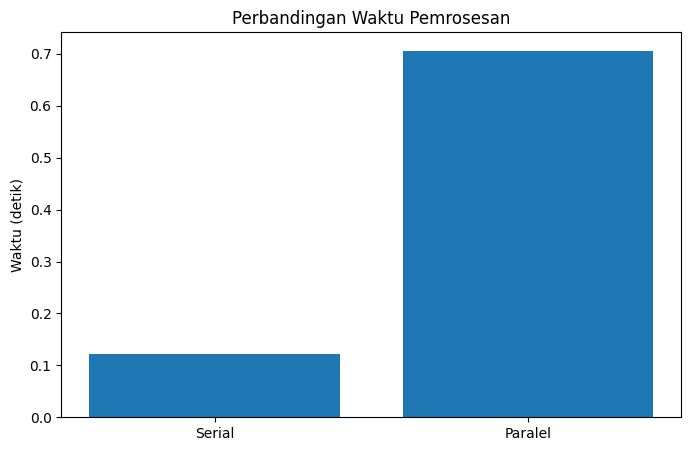

In [6]:
print("===== PERBANDINGAN PERFORMA =====")
print(f"Serial  : {waktu_serial:.4f} detik")
print(f"Paralel : {waktu_paralel:.4f} detik")

if waktu_paralel < waktu_serial:
    percepatan = waktu_serial / waktu_paralel
    print(f"Percepatan: {percepatan:.2f} kali")
    print("Pemrosesan paralel lebih cepat pada percobaan ini.")
else:
    perlambatan = waktu_paralel / waktu_serial
    print(f"Rasio waktu serial terhadap paralel: {1/perlambatan:.2f}")
    print("Pemrosesan paralel belum lebih cepat pada percobaan ini.")

sama = np.allclose(hasil_serial, hasil_paralel)
print("Hasil kedua metode sama:", sama)

plt.figure(figsize=(8, 5))
plt.bar(
    ["Serial", "Paralel"],
    [waktu_serial, waktu_paralel]
)
plt.title("Perbandingan Waktu Pemrosesan")
plt.ylabel("Waktu (detik)")
plt.show()